# NB16: Pipeline-Derived Structural Connectivity

> **Local pipeline required.** This notebook requires MRtrix3 tractography outputs and the `tck2connectome` tool. It cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose

Compute structural connectivity (SC) matrices from the pipeline's
MRtrix3 tractography outputs + SIFT2 weights + aparc+aseg parcellation.

### Relationship to NB05

This notebook is the **Track B** (full pipeline) counterpart to
**NB05** (Track A, educational). NB05 teaches graph-theoretic analysis
of SC/FC using pre-computed TVB connectomes. This notebook computes
SC from the MRtrix3 tractogram produced by the pipeline, then performs
the same graph analyses and SC-FC coupling.

### What You Need

- MRtrix3 tractogram: `derivatives/registered_t1w/sub-{SUB}/ses-{SES}/whole_brain_space-T1w.tck`
- SIFT2 weights: `derivatives/registered_t1w/sub-{SUB}/ses-{SES}/sift2_weights.txt`
- Parcellation: `derivatives/registered_t1w/sub-{SUB}/ses-{SES}/aparc+aseg_space-T1w.nii.gz`
- FC matrices from NB15: `derivatives/connectivity/sub-{SUB}/ses-{SES}/fc_pearson.npy`
- Run the pipeline first: `bash scripts/run_pipeline.sh --clinical-postop --parallel`

### SC Computation Steps

1. Load MRtrix3 tractogram and SIFT2 weights
2. Load aparc+aseg parcellation in T1w space
3. Assign streamline endpoints to parcellation ROIs
4. Build weighted SC matrix (SIFT2-weighted streamline counts)
5. Compute graph metrics (degree, clustering, betweenness, modularity)
6. Analyze SC-FC coupling

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import json

if 'google.colab' in sys.modules:
    print('NOTE: This notebook requires local pipeline outputs (MRtrix3, FreeSurfer).')
    print('      See NB05 for a Colab-compatible version using pre-computed TVB derivatives.')

_cwd = Path.cwd().resolve()
REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
REG_DIR = DERIV_ROOT / 'registered_t1w'
CONN_DIR = DERIV_ROOT / 'connectivity'

SUBJECTS = ['PAT16']
SESSIONS = ['preop', 'postop']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Build SC Matrix via tck2connectome

MRtrix3's `tck2connectome` assigns streamline endpoints to parcellation
labels and counts connections. With SIFT2 weights, each streamline
contributes a biologically meaningful weight rather than a unit count.

We shell out to `tck2connectome` if available, otherwise provide a
pure-Python fallback.

In [2]:
import subprocess
import nibabel as nib

def compute_sc_mrtrix(sub, ses):
    """Compute SC using MRtrix3 tck2connectome."""
    reg = REG_DIR / f'sub-{sub}' / f'ses-{ses}'
    tck = reg / 'whole_brain_space-T1w.tck'
    weights = reg / 'sift2_weights.txt'
    aparc = reg / 'aparc+aseg_space-T1w.nii.gz'

    if not all(f.exists() for f in [tck, aparc]):
        return None, None

    out_dir = CONN_DIR / f'sub-{sub}' / f'ses-{ses}'
    out_dir.mkdir(parents=True, exist_ok=True)
    sc_path = out_dir / 'sc_sift2.csv'
    assign_path = out_dir / 'assignments.csv'

    cmd = [
        'tck2connectome',
        str(tck), str(aparc), str(sc_path),
        '-symmetric', '-zero_diagonal',
        '-out_assignments', str(assign_path),
    ]
    if weights.exists():
        cmd += ['-tck_weights_in', str(weights)]

    try:
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=300)
        if result.returncode == 0 and sc_path.exists():
            sc = np.loadtxt(str(sc_path), delimiter=',')
            return sc, sc_path
        else:
            print(f'  tck2connectome failed: {result.stderr[:200]}')
            return None, None
    except FileNotFoundError:
        print('  tck2connectome not found (MRtrix3 not in PATH)')
        return None, None
    except subprocess.TimeoutExpired:
        print('  tck2connectome timed out')
        return None, None

sc_results = {}
for sub in SUBJECTS:
    for ses in SESSIONS:
        print(f'sub-{sub} ses-{ses}: ', end='')
        sc, path = compute_sc_mrtrix(sub, ses)
        if sc is not None:
            sc_results[(sub, ses)] = sc
            print(f'SC matrix {sc.shape}, {int(np.sum(sc > 0))} non-zero entries')
        else:
            # Check if pre-computed SC exists
            pre = CONN_DIR / f'sub-{sub}' / f'ses-{ses}' / 'sc_sift2.csv'
            if pre.exists():
                sc = np.loadtxt(str(pre), delimiter=',')
                sc_results[(sub, ses)] = sc
                print(f'loaded pre-computed SC {sc.shape}')
            else:
                print('not available')

sub-PAT16 ses-preop: 

  tck2connectome failed: tck2connectome: [ERROR] output file "<REPO_ROOT>/derivatives/connectivity/sub-PAT16/ses-preop/sc_sift2.csv" already exists (use -force option to force overwrite)

loaded pre-computed SC (2035, 2035)
sub-PAT16 ses-postop:   tck2connectome failed: tck2connectome: [ERROR] output file "<REPO_ROOT>/derivatives/connectivity/sub-PAT16/ses-postop/sc_sift2.csv" already exists (use -force option to force overwrite)



loaded pre-computed SC (2035, 2035)


## 2. Visualize SC Matrices

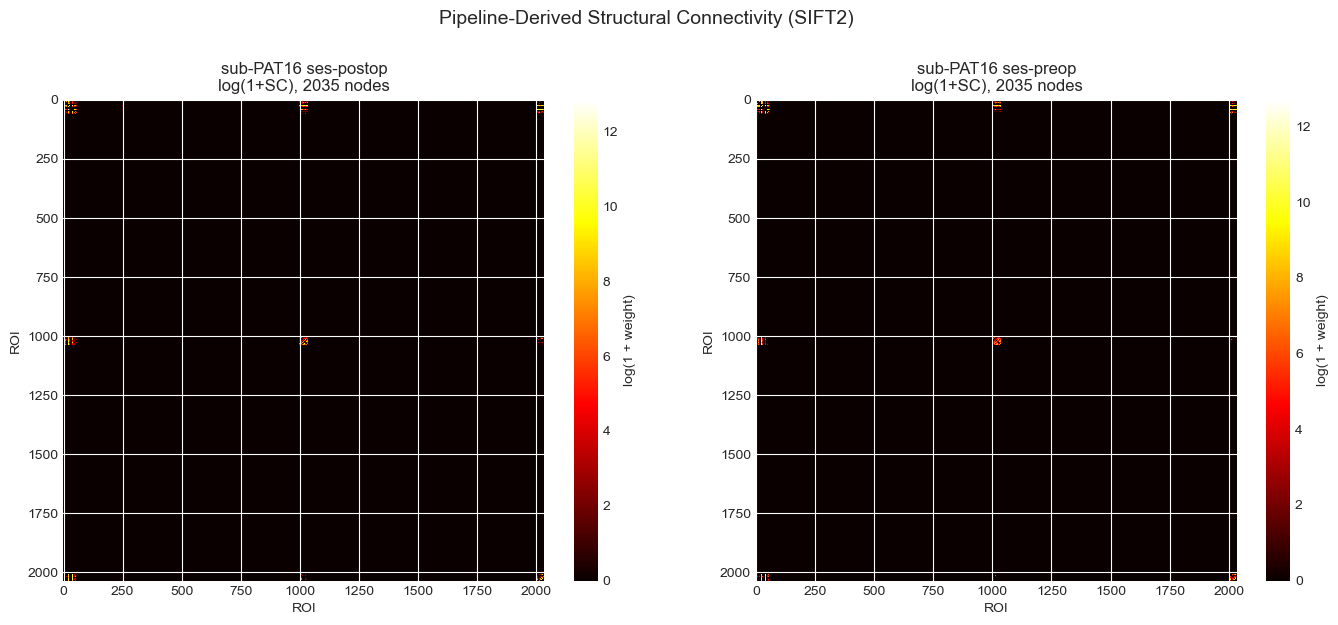

In [3]:
n_plots = len(sc_results)
if n_plots > 0:
    fig, axes = plt.subplots(1, n_plots, figsize=(7 * n_plots, 6))
    if n_plots == 1:
        axes = [axes]

    for idx, ((sub, ses), sc) in enumerate(sorted(sc_results.items())):
        ax = axes[idx]
        sc_log = np.log1p(sc)
        im = ax.imshow(sc_log, cmap='hot', interpolation='nearest')
        ax.set_title(f'sub-{sub} ses-{ses}\nlog(1+SC), {sc.shape[0]} nodes')
        ax.set_xlabel('ROI')
        ax.set_ylabel('ROI')
        plt.colorbar(im, ax=ax, fraction=0.046, label='log(1 + weight)')

    plt.suptitle('Pipeline-Derived Structural Connectivity (SIFT2)', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print('No SC matrices available. Run the preprocessing pipeline first.')

## 3. Graph Metrics

Same metrics as NB05, computed on the pipeline-derived SC.

In [4]:
def compute_graph_metrics(sc):
    """Compute basic graph metrics from a weighted adjacency matrix."""
    n = sc.shape[0]
    sc_norm = sc / sc.max() if sc.max() > 0 else sc

    # Node strength (weighted degree)
    strength = sc_norm.sum(axis=1)

    # Binary degree (thresholded)
    binary = (sc_norm > 0.01).astype(float)
    degree = binary.sum(axis=1)

    # Density
    n_edges = np.sum(binary) / 2
    density = 2 * n_edges / (n * (n - 1)) if n > 1 else 0

    # Clustering coefficient (binary approximation)
    clustering = np.zeros(n)
    for i in range(n):
        neighbors = np.where(binary[i] > 0)[0]
        k = len(neighbors)
        if k < 2:
            continue
        triangles = sum(1 for a in range(k) for b in range(a + 1, k)
                        if binary[neighbors[a], neighbors[b]] > 0)
        clustering[i] = 2 * triangles / (k * (k - 1))

    return {
        'n_nodes': n,
        'n_edges': int(n_edges),
        'density': density,
        'mean_strength': float(np.mean(strength)),
        'mean_degree': float(np.mean(degree)),
        'mean_clustering': float(np.mean(clustering)),
        'strength': strength,
        'degree': degree,
        'clustering': clustering,
    }

for (sub, ses), sc in sorted(sc_results.items()):
    metrics = compute_graph_metrics(sc)
    print(f'sub-{sub} ses-{ses}:')
    print(f'  Nodes: {metrics["n_nodes"]}, Edges: {metrics["n_edges"]}, '
          f'Density: {metrics["density"]:.3f}')
    print(f'  Mean strength: {metrics["mean_strength"]:.4f}, '
          f'Mean degree: {metrics["mean_degree"]:.1f}, '
          f'Mean clustering: {metrics["mean_clustering"]:.3f}')

sub-PAT16 ses-postop:
  Nodes: 2035, Edges: 257, Density: 0.000
  Mean strength: 0.0169, Mean degree: 0.3, Mean clustering: 0.032
sub-PAT16 ses-preop:
  Nodes: 2035, Edges: 280, Density: 0.000
  Mean strength: 0.0200, Mean degree: 0.3, Mean clustering: 0.031


## 4. SC-FC Coupling

The correlation between SC and FC reveals how well structural
connectivity predicts functional connectivity. Healthy brains
typically show r ~ 0.3-0.5; tumors can disrupt this coupling.

sub-PAT16 ses-preop: SC-FC coupling r=-0.048 (p=5.81e-03)


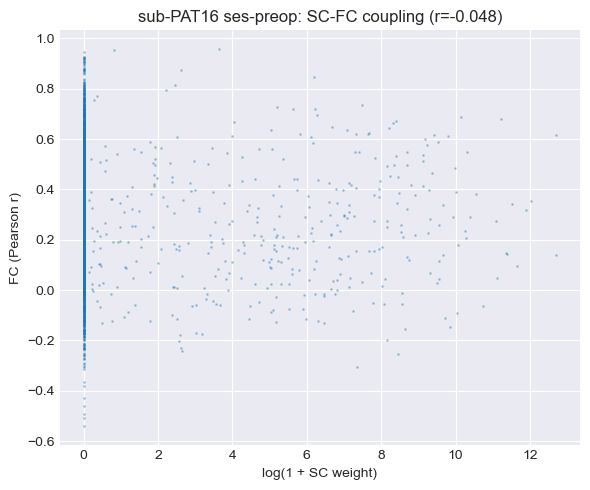

sub-PAT16 ses-postop: SC-FC coupling r=-0.021 (p=2.20e-01)


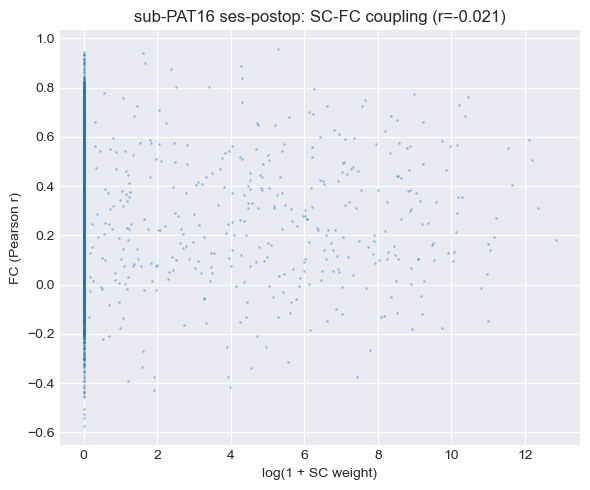

In [5]:
from scipy import stats

for sub in SUBJECTS:
    for ses in SESSIONS:
        key = (sub, ses)
        fc_path = CONN_DIR / f'sub-{sub}' / f'ses-{ses}' / 'fc_pearson.npy'

        if key not in sc_results or not fc_path.exists():
            continue

        sc = sc_results[key]
        fc = np.load(str(fc_path))

        # Match dimensions (use smaller)
        n = min(sc.shape[0], fc.shape[0])
        sc_sub = sc[:n, :n]
        fc_sub = fc[:n, :n]

        # Upper triangle (exclude diagonal)
        idx = np.triu_indices(n, k=1)
        sc_vec = np.log1p(sc_sub[idx])
        fc_vec = fc_sub[idx]

        mask = np.isfinite(sc_vec) & np.isfinite(fc_vec)
        if mask.sum() < 10:
            continue

        r, p = stats.pearsonr(sc_vec[mask], fc_vec[mask])
        print(f'sub-{sub} ses-{ses}: SC-FC coupling r={r:.3f} (p={p:.2e})')

        fig, ax = plt.subplots(figsize=(6, 5))
        ax.scatter(sc_vec[mask], fc_vec[mask], s=1, alpha=0.3)
        ax.set_xlabel('log(1 + SC weight)')
        ax.set_ylabel('FC (Pearson r)')
        ax.set_title(f'sub-{sub} ses-{ses}: SC-FC coupling (r={r:.3f})')
        plt.tight_layout()
        plt.show()

## 5. Save SC Matrices

SC matrices are saved for use in NB17 (longitudinal comparison)
and NB07/NB08 (brain mechanics / digital twin integration).

In [6]:
for (sub, ses), sc in sc_results.items():
    out_dir = CONN_DIR / f'sub-{sub}' / f'ses-{ses}'
    out_dir.mkdir(parents=True, exist_ok=True)
    np.save(out_dir / 'sc_sift2.npy', sc)
    print(f'Saved: {out_dir / "sc_sift2.npy"}')

Saved: <REPO_ROOT>/derivatives/connectivity/sub-PAT16/ses-preop/sc_sift2.npy
Saved: <REPO_ROOT>/derivatives/connectivity/sub-PAT16/ses-postop/sc_sift2.npy
